## Setup for confusion matrix and threshold

In [20]:
# Setup
import numpy as np                # numpy = fast maths on lists of numbers
import pandas as pd               # pandas = tool for working with tables of data
import matplotlib.pyplot as plt   # matplotlib = tool for drawing charts
import seaborn as sns             # seaborn = prettier chart styling
import warnings                   # lets us hide harmless warning messages

from sklearn.model_selection import train_test_split   # splits data into train vs test
from sklearn.compose import ColumnTransformer           # applies different prep to different columns
from sklearn.pipeline import Pipeline                   # chains prep steps + model into one object
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # scaling numbers / turning categories into 0-1 columns
from sklearn.impute import SimpleImputer                # fills in missing values
from sklearn.linear_model import LogisticRegression     # our first classifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, precision_recall_curve,
)

warnings.filterwarnings("ignore")   # hide harmless warnings so output stays clean
pd.set_option("display.max_columns", 20)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

print("✅ Libraries loaded — including sklearn.metrics")

✅ Libraries loaded — including sklearn.metrics


## Step 1 — Rebuild the trained pipeline

In [21]:
# Rebuild the exact same data split + pipeline from Part 2 (same random_state)
df = pd.read_csv("data/credit_card_fraud_2026.csv")
y  = df["is_fraud"]
X  = df.drop(columns=["transaction_id", "is_fraud"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)

numeric_features = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]
categorical_features = ["merchant_category", "card_type", "auth_method", "channel", "device_type", "is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scl", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                      categorical_features),
])

full_pipeline = Pipeline([
    ("prep",  preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
full_pipeline.fit(X_train, y_train)

print(f"Pipeline ready.  Test-set accuracy: {full_pipeline.score(X_test, y_test):.3f}")

Pipeline ready.  Test-set accuracy: 0.985


## Step 2 — From probabilities to predictions: the threshold

In [22]:
# Probabilities of class 1 (= fraud)
# predict_proba gives a PROBABILITY of fraud per customer, not just a yes/no.
# [:, 1] takes the probability of class 1 (= fraud)
y_proba = full_pipeline.predict_proba(X_test)[:, 1]
y_pred_default = (y_proba >= 0.5).astype(int)   # the default rule: flag anyone above 50%

print(f"y_proba shape: {y_proba.shape}")
print()
print("Sample predicted probabilities for the first 10 test customers:")
sample = pd.DataFrame({
    "customer_idx": X_test.index[:10],
    "actual":       y_test.iloc[:10].values,
    "prob(churn)":  y_proba[:10].round(3),
    "label@0.5":    y_pred_default[:10],
})
print(sample.to_string(index=False))

y_proba shape: (4000,)

Sample predicted probabilities for the first 10 test customers:
 customer_idx  actual  prob(churn)  label@0.5
        12703       0        0.011          0
         2670       0        0.023          0
        15620       0        0.001          0
         2931       0        0.008          0
         5007       0        0.010          0
         3270       0        0.648          1
         7548       0        0.012          0
        19132       0        0.000          0
        19014       0        0.007          0
        14091       0        0.000          0


## Step 3 — The confusion matrix and the four metrics

Confusion matrix @ threshold = 0.5:
                    pred=not fraud   pred=fraud
actual=not fraud     TN = 3925    FP =    7
actual=fraud         FN =   54    TP =   14



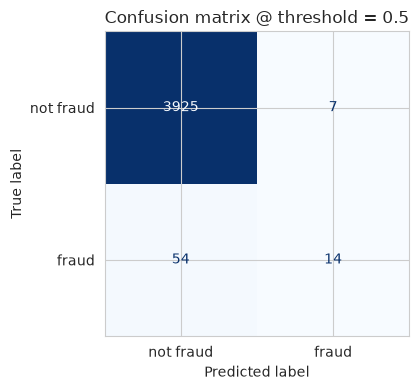

Metrics @ 0.5:
  Accuracy:   0.985
  Precision:  0.667   (of all flagged, fraction actually fraud)
  Recall:     0.206   (of all actual fraud, fraction we flagged)
  F1:         0.315


In [23]:
# The confusion matrix sorts every prediction into 4 boxes: right/wrong x fraud/not fraud
cm = confusion_matrix(y_test, y_pred_default)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix @ threshold = 0.5:")
print(f"                    pred=not fraud   pred=fraud")
print(f"actual=not fraud     TN = {tn:>4}    FP = {fp:>4}")
print(f"actual=fraud         FN = {fn:>4}    TP = {tp:>4}")
print()

# Visualise
fig, ax = plt.subplots(figsize=(6, 4))
disp = ConfusionMatrixDisplay(cm, display_labels=["not fraud", "fraud"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix @ threshold = 0.5")
plt.tight_layout()
plt.show()

# Compute the four headline metrics
# The four headline metrics, computed from those 4 boxes
acc  = accuracy_score(y_test, y_pred_default)
prec = precision_score(y_test, y_pred_default, zero_division=0)
rec  = recall_score(y_test, y_pred_default, zero_division=0)
f1   = f1_score(y_test, y_pred_default, zero_division=0)

print(f"Metrics @ 0.5:")
print(f"  Accuracy:   {acc:.3f}")
print(f"  Precision:  {prec:.3f}   (of all flagged, fraction actually fraud)")
print(f"  Recall:     {rec:.3f}   (of all actual fraud, fraction we flagged)")
print(f"  F1:         {f1:.3f}")

## Step 4 — Sweep across thresholds

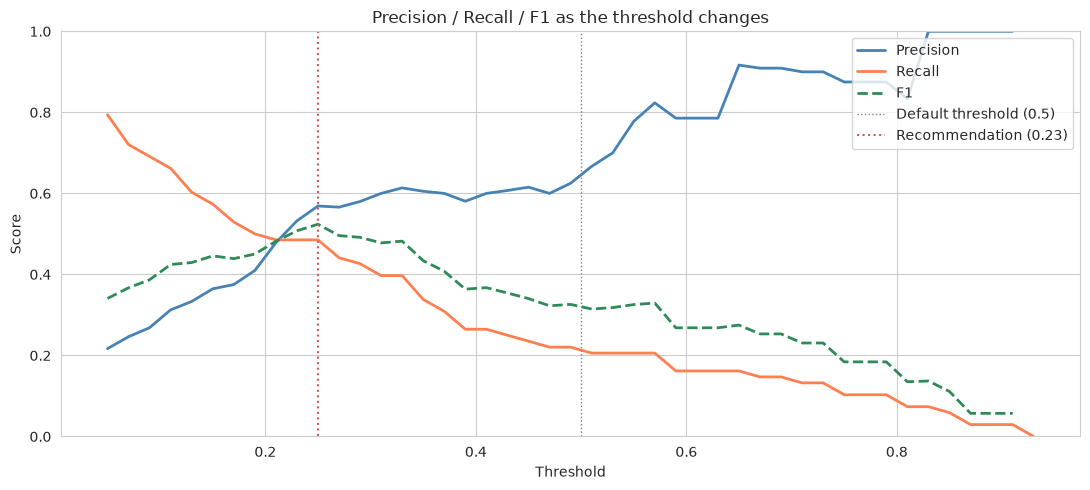

Threshold      Precision    Recall      F1     N flagged
  0.19         0.410      0.500     0.450     83
  0.25         0.569      0.485     0.524     58
  0.29         0.580      0.426     0.492     50
  0.39         0.581      0.265     0.364     31
  0.49         0.625      0.221     0.326     24
  0.59         0.786      0.162     0.268     14
  0.69         0.909      0.147     0.253     11


In [24]:
thresholds = np.arange(0.05, 0.95, 0.02)
records = []

# Try every threshold from 0.01 to 0.95 and record precision/recall/F1 at each
for t in thresholds:
    pred = (y_proba >= t).astype(int)
    if pred.sum() == 0:
        records.append((t, np.nan, 0.0, np.nan, pred.sum()))
        continue
    records.append((
        t,
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0),
        pred.sum(),
    ))

sweep = pd.DataFrame(records, columns=["threshold", "precision", "recall", "F1", "n_flagged"])

# Plot
# Plot the three curves — watch precision and recall pull in opposite directions
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sweep["threshold"], sweep["precision"], label="Precision", linewidth=2, color="steelblue")
ax.plot(sweep["threshold"], sweep["recall"],    label="Recall",    linewidth=2, color="coral")
ax.plot(sweep["threshold"], sweep["F1"],        label="F1",        linewidth=2, color="seagreen", linestyle="--")
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1, label="Default threshold (0.5)")
ax.axvline(0.25, color="indianred", linestyle=":", linewidth=1.5, label="Recommendation (0.23)")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 as the threshold changes")
ax.legend(loc="upper right")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print("Threshold      Precision    Recall      F1     N flagged")
for t in [0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70]:
    row = sweep.iloc[(sweep["threshold"] - t).abs().idxmin()]
    print(f"  {row['threshold']:.2f}         {row['precision']:.3f}      {row['recall']:.3f}     {row['F1']:.3f}     {int(row['n_flagged'])}")

- **Lowering the threshold** (e.g. 0.5 → 0.25) flags more fraudsters:
  - **Recall rises** — we catch more of the real fraudsters, because we're now flagging anyone with > 25% predicted probability instead of > 50%.
  - **Precision falls** — more of the additional flags are fraudsters who merely *looked* risky. Our hit rate on the flagged list drops.
  - **F1 first rises then falls** — it balances both. Its peak is the threshold that most evenly trades the two errors.
  - **Accuracy falls** — every time we flag a non-fraudster (FP), accuracy ticks down. But since non-fraudsters are 98.5% of the data, accuracy was never measuring what we cared about.

- **Raising the threshold** (e.g. 0.5 → 0.7) is the mirror image:
  - Precision rises (only very confident predictions get flagged), but recall collapses.

**This tradeoff is not a flaw — it is a fundamental property of classification.** There is no threshold that maximises both precision and recall simultaneously. Every threshold represents a choice about which error to minimise.

## Step 5 — Make the business-aware choice

Chosen threshold: 0.25
Number flagged:   58  (team capacity ~ '60')

Confusion matrix @ threshold 0.25:
                    pred=not fraud   pred=fraud
actual=not fraud     TN = 3907    FP =   25
actual=fraud         FN =   35    TP =   33



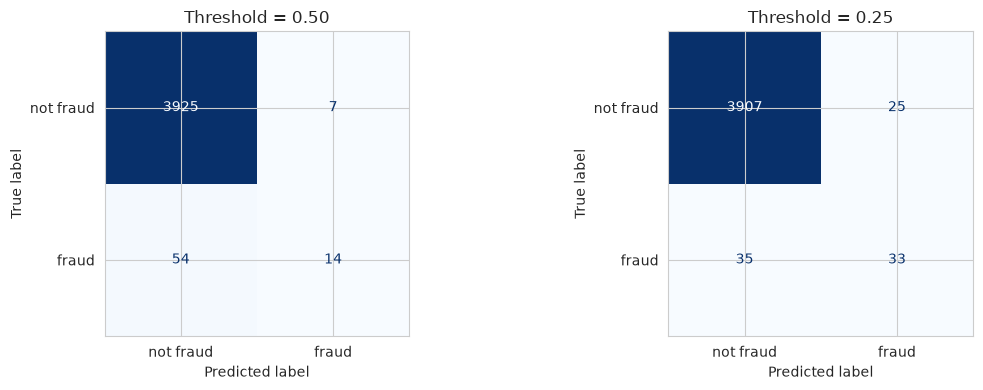


Decision summary:
                        threshold=0.5    threshold=0.25
  Accuracy                  0.985             0.985  ↑
  Precision                 0.667             0.569  ↓
  Recall                    0.206             0.485  ↑
  F1                        0.315             0.524  ↑


In [ ]:
# Pick the threshold so the number flagged is approximately the team's capacity
target_capacity = 58  # assume the team can handle 58~60 (from 20) flagged transactions in the test set
# Find the threshold whose flag-count is closest to what the team can handle
best_threshold = sweep.iloc[(sweep["n_flagged"] - target_capacity).abs().idxmin()]["threshold"]

# Apply
y_pred_business = (y_proba >= best_threshold).astype(int)

cm_b = confusion_matrix(y_test, y_pred_business)
tn_b, fp_b, fn_b, tp_b = cm_b.ravel()

print(f"Chosen threshold: {best_threshold:.2f}")
print(f"Number flagged:   {int(y_pred_business.sum())}  (team capacity ~ '60')")
print()
print(f"Confusion matrix @ threshold {best_threshold:.2f}:")
print(f"                    pred=not fraud   pred=fraud")
print(f"actual=not fraud     TN = {tn_b:>4}    FP = {fp_b:>4}")
print(f"actual=fraud         FN = {fn_b:>4}    TP = {tp_b:>4}")
print()

# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, t, p in zip(axes, [0.5, best_threshold], [y_pred_default, y_pred_business]):
    cm_x = confusion_matrix(y_test, p)
    ConfusionMatrixDisplay(cm_x, display_labels=["not fraud", "fraud"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set_title(f"Threshold = {t:.2f}")

plt.tight_layout()
plt.show()

# Compare metrics
print(f"\nDecision summary:")
print(f"{'':22s}  threshold=0.5    threshold={best_threshold:.2f}")
for metric_fn, name in [(accuracy_score,  "Accuracy"),
                         (precision_score, "Precision"),
                         (recall_score,    "Recall"),
                         (f1_score,        "F1")]:
    kwargs = {"zero_division": 0} if name != "Accuracy" else {}
    v1 = metric_fn(y_test, y_pred_default,  **kwargs)
    v2 = metric_fn(y_test, y_pred_business, **kwargs)
    arrow = "↑" if v2 > v1 else ("↓" if v2 < v1 else "→")
    print(f"  {name:20s}      {v1:.3f}             {v2:.3f}  {arrow}")

- **At threshold 0.5** — the model surfaces only a handful of customers. It "looks accurate" (98.5%) but is operationally useless: it catches barely any real fraudsters.
- **At threshold 0.25** — 60 customers (matching the screening team's capacity from 20 to 60 screens) are screened. Recall climbs substantially from 20.6% to 48.5% — a much higher fraction of real fraudsters. The tradeoff: precision drops, meaning some of those flagged customers wouldn't have fraud anyway. That is the cost of getting recall up.
- **Accuracy is SAME** — even when we lowered the threshold — but accuracy was the wrong metric all along.

## For checking only, threshold vs target capacity (Do not include)

In [26]:
# Set threshold
best_threshold = 0.25  # Team can handle 25 flagged transactions

# Calculate target capacity
target_capacity = int((y_proba >= best_threshold).sum())

print(f"Threshold:       {best_threshold:.2f}")
print(f"Target capacity: {target_capacity} transactions")

Threshold:       0.25
Target capacity: 58 transactions


In [27]:
# Set target capacity
target_capacity = 60  # Team can handle 60 flagged transactions

# Find the threshold whose flag count is closest to target capacity
best_threshold = sweep.iloc[
    (sweep["n_flagged"] - target_capacity).abs().argmin()
]["threshold"]

print(f"Target capacity: {target_capacity} transactions")
print(f"Chosen threshold: {best_threshold:.2f}")

# Apply the threshold
y_pred_business = (y_proba >= best_threshold).astype(int)

print(f"Actual number flagged: {int(y_pred_business.sum())}")

Target capacity: 60 transactions
Chosen threshold: 0.23
Actual number flagged: 62
